<img src="https://raw.githubusercontent.com/drdave-teaching/OPIM5509-notebooks/main/_banners/opim5509_banner.svg" width="100%" alt="OPIM 5509 banner"/>

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/drdave-teaching/OPIM5509-notebooks/blob/main/FinalProject/FP1_Basic_LSTM_Forecast.ipynb)

# Final Project, Part 1: A Basic LSTM Forecast of Connecticut's Electricity Load
--------------------------------------------------
**Dr. Dave Wanik - University of Connecticut**

Your final project is a **live forecast**. Every hour, a model you trained will predict Connecticut's electricity
load for the next 24 hours, and a class leaderboard will score it against what actually happened. This notebook is
Part 1: build a basic LSTM, check that it beats a simple baseline, and save it so it can run in the cloud. Part 2
(`FP2_Probabilistic_LSTM`) adds a range - a low, expected and high forecast - which is what the leaderboard scores.

| Part | What | Time |
| :-- | :-- | --: |
| 0 | Before you start | 2 min |
| 1 | Load the data | 3 min |
| 2 | Look at it | 10 min |
| 3 | Turn it into sequences | 10 min |
| 4 | The baseline to beat | 5 min |
| 5 | Build and fit the LSTM | 15 min |
| 6 | Score it like the leaderboard | 10 min |
| 7 | Save it for the cloud | 5 min |

## Part 0 · Before you start
**Runtime > Change runtime type > T4 GPU.** The LSTM trains in about a minute on a GPU and about five on a CPU.

In [1]:
import json
import time

import keras
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from keras import layers
from pandas.tseries.holiday import USFederalHolidayCalendar

SETTINGS = {
    "seed": 5509,
    "lookback_hours": 168,          # the LSTM reads the past week of load, one hour at a time
    "horizon_hours": 24,            # and forecasts the next 24 hours
    "train_end_utc": "2026-01-01",  # train on 2023-2025, test on 2026 (data the model never saw)
    "units": 64,
    "epochs": 30,
    "batch_size": 128,
    "patience": 3,
}

keras.utils.set_random_seed(SETTINGS["seed"])
tf.config.experimental.enable_op_determinism()
print("Keras", keras.__version__, "| GPU:", len(tf.config.list_physical_devices("GPU")) > 0)

Keras 3.15.1 | GPU: False


## Part 1 · Load the data
One row per hour from January 2023 to October 2026: Connecticut's electricity load (`load_mw`, from ISO New England)
and the weather at Bradley airport. It is the same file the OPIM 5512 class uses. All times are in UTC (`hour_utc` =
the hour the value begins), so daylight saving never duplicates or drops a row.

In [2]:
URL = "https://raw.githubusercontent.com/drdave-teaching/OPIM5512-notebooks/main/Module4/data/bdl_ct_load_hourly_2023_2026.csv"
df = pd.read_csv(URL, parse_dates=["hour_utc"])
df = df.set_index("hour_utc").sort_index()

# make every hour exist, so "168 rows back" always means "168 hours back"
all_hours = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(all_hours)
print(df.shape, "| from", df.index.min(), "to", df.index.max())
print("hours with no load:", int(df["load_mw"].isna().sum()))
df[["load_mw", "temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]].describe().round(1)

(33215, 17) | from 2023-01-01 05:00:00+00:00 to 2026-10-16 03:00:00+00:00
hours with no load: 0


,load_mw,temp_f,dewpoint_f,rel_humidity_pct,wind_speed_mph,cloud_cover_pct
count,33215.0,33215.0,33215.0,33215.0,33215.0,33215.0
mean,3062.8,53.6,41.3,66.3,7.4,61.4
std,686.9,18.7,19.0,20.1,5.1,34.9
min,1682.7,-9.0,-29.0,9.6,0.0,0.0
25%,2569.7,39.0,27.0,50.6,4.6,19.0
50%,2965.8,54.0,43.0,67.0,6.9,75.0
75%,3438.9,69.0,57.0,84.2,10.4,100.0
max,6485.8,99.0,78.0,100.0,34.5,100.0


## Part 2 · Look at it
Three patterns the model has to learn: a **daily rhythm** (people wake up, go to work, come home), a **yearly
rhythm**, and a **U-shape with temperature** (heating in winter, air conditioning in summer).

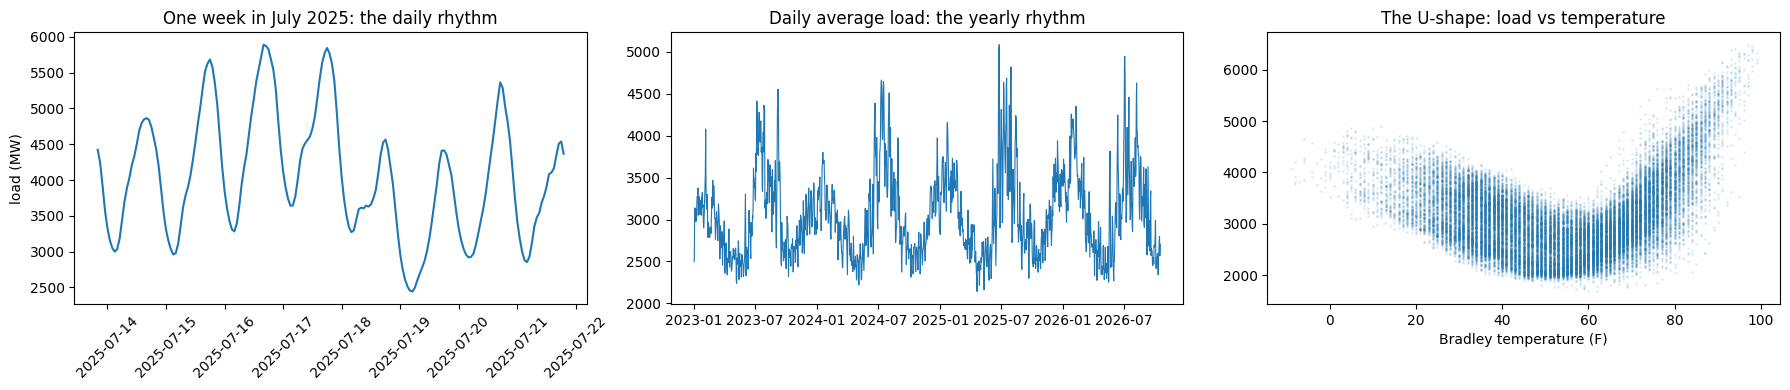

In [3]:
local = df.index.tz_convert("America/New_York")
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

week = df.loc["2025-07-14":"2025-07-21", "load_mw"]
axes[0].plot(week.index.tz_convert("America/New_York"), week.values)
axes[0].set_title("One week in July 2025: the daily rhythm")
axes[0].set_ylabel("load (MW)")
axes[0].tick_params(axis="x", rotation=45)

daily = df["load_mw"].resample("D").mean()
axes[1].plot(daily.index, daily.values, linewidth=0.8)
axes[1].set_title("Daily average load: the yearly rhythm")

axes[2].scatter(df["temp_f"], df["load_mw"], s=1, alpha=0.1)
axes[2].set_title("The U-shape: load vs temperature")
axes[2].set_xlabel("Bradley temperature (F)")
plt.tight_layout()
plt.show()

## Part 3 · Turn it into sequences
At **issue hour T** (the hour the forecast is made), the model gets two inputs and makes one output:

* **The past:** the 168 hours before T - the load plus the hour of the day (as a sine and a cosine, so 11 PM sits
  next to midnight). Shape `(168, 3)`.
* **The future it is told about:** the 24 hours from T+1 to T+24 - the weather forecast for those hours plus the
  calendar (hour of day, day of week, time of year, weekend, holiday). Shape `(24, 13)`.
* **The answer:** the load for those 24 hours. Shape `(24,)`.

In training we use the weather that actually happened as the "forecast". In the cloud the model gets a real
forecast, which is less accurate - Part 2 deals with that.

Everything is **scaled** with means and standard deviations from the training years only, and those numbers are saved
with the model, so the cloud scales new data exactly the same way.

`make_inputs` below is the **contract** between this notebook and the cloud: the cloud function runs this exact code.
If you change it (new features, a longer look-back), you change it there too.

In [4]:
WEATHER = ["temp_f", "dewpoint_f", "rel_humidity_pct", "wind_speed_mph", "cloud_cover_pct"]
HOLIDAYS = USFederalHolidayCalendar().holidays(start="2020-01-01", end="2030-12-31")


def calendar_features(hours_utc):
    """Hour of day, day of week and time of year as sines and cosines, plus weekend and holiday flags, in Connecticut time."""
    local = pd.DatetimeIndex(hours_utc).tz_convert("America/New_York")
    out = pd.DataFrame(index=pd.DatetimeIndex(hours_utc))
    out["hour_sin"] = np.sin(2 * np.pi * local.hour / 24)
    out["hour_cos"] = np.cos(2 * np.pi * local.hour / 24)
    out["dow_sin"] = np.sin(2 * np.pi * local.dayofweek / 7)
    out["dow_cos"] = np.cos(2 * np.pi * local.dayofweek / 7)
    out["doy_sin"] = np.sin(2 * np.pi * local.dayofyear / 365.25)
    out["doy_cos"] = np.cos(2 * np.pi * local.dayofyear / 365.25)
    out["is_weekend"] = (local.dayofweek >= 5).astype(float)
    out["is_holiday"] = local.tz_localize(None).normalize().isin(HOLIDAYS).astype(float)
    return out


def make_inputs(issue_hour_utc, load, weather, card):
    """The model's two inputs for ONE forecast issued at issue_hour_utc.
    load: Connecticut load in MW indexed by UTC hour (only hours that are over).
    weather: the WEATHER columns indexed by UTC hour, covering the next 24 hours.
    card: the model card (look-back, horizon and the scaling numbers).
    Returns past (lookback, 3) and future (horizon, 13), both scaled."""
    issue = pd.Timestamp(issue_hour_utc)
    past_hours = pd.date_range(issue - pd.Timedelta(hours=card["lookback_hours"]), periods=card["lookback_hours"], freq="h")
    future_hours = pd.date_range(issue + pd.Timedelta(hours=1), periods=card["horizon_hours"], freq="h")
    past_load = (load.reindex(past_hours).values - card["load_mean"]) / card["load_std"]
    past_cal = calendar_features(past_hours)[["hour_sin", "hour_cos"]].values
    past = np.column_stack([past_load, past_cal])
    future_weather = weather[WEATHER].reindex(future_hours)
    scaled_weather = []
    for column in WEATHER:
        scaled_weather.append((future_weather[column].values - card["weather_mean"][column]) / card["weather_std"][column])
    future = np.column_stack(scaled_weather + [calendar_features(future_hours).values])
    return past.astype("float32"), future.astype("float32")

Now the scaling numbers (training years only) and one sample per issue hour. An hour is kept only if its whole past
week and its next 24 hours exist.

In [5]:
train_end = pd.Timestamp(SETTINGS["train_end_utc"], tz="UTC")
is_train_hour = df.index < train_end
card = {
    "model_type": "keras_lstm",
    "lookback_hours": SETTINGS["lookback_hours"],
    "horizon_hours": SETTINGS["horizon_hours"],
    "weather_columns": WEATHER,
    "load_mean": float(df.loc[is_train_hour, "load_mw"].mean()),
    "load_std": float(df.loc[is_train_hour, "load_mw"].std()),
    "weather_mean": {},
    "weather_std": {},
}
for column in WEATHER:
    card["weather_mean"][column] = float(df.loc[is_train_hour, column].mean())
    card["weather_std"][column] = float(df.loc[is_train_hour, column].std())

load = df["load_mw"]
weather = df[WEATHER]
lookback = SETTINGS["lookback_hours"]
horizon = SETTINGS["horizon_hours"]

start = time.time()
# make_inputs builds ONE forecast. For 33,000 training samples it is much faster to build the same numbers for every
# hour at once, slide a window over them, and then check a few samples against make_inputs (the code the cloud runs).
hours = df.index
load_scaled = (load.values - card["load_mean"]) / card["load_std"]
scaled_weather = []
for column in WEATHER:
    scaled_weather.append((weather[column].values - card["weather_mean"][column]) / card["weather_std"][column])
calendar = calendar_features(hours)
every_hour_past = np.column_stack([load_scaled, calendar[["hour_sin", "hour_cos"]].values]).astype("float32")
every_hour_future = np.column_stack(scaled_weather + [calendar.values]).astype("float32")

windows_past = np.lib.stride_tricks.sliding_window_view(every_hour_past, lookback, axis=0)        # window k = hours k ... k+167
windows_future = np.lib.stride_tricks.sliding_window_view(every_hour_future, horizon, axis=0)    # window k = hours k ... k+23
windows_load = np.lib.stride_tricks.sliding_window_view(load_scaled.astype("float32"), horizon)
issue_positions = np.arange(lookback, len(hours) - horizon)
past_all = windows_past[issue_positions - lookback].transpose(0, 2, 1)        # the 168 hours before the issue hour
future_all = windows_future[issue_positions + 1].transpose(0, 2, 1)           # the 24 hours after it
y_all = windows_load[issue_positions + 1]
missing = np.isnan(past_all).any(axis=(1, 2)) | np.isnan(future_all).any(axis=(1, 2)) | np.isnan(y_all).any(axis=1)
X_past = np.ascontiguousarray(past_all[~missing])
X_future = np.ascontiguousarray(future_all[~missing])
y = np.ascontiguousarray(y_all[~missing])
issue_hours = hours[issue_positions[~missing]]
train = issue_hours < train_end

# the check: 5 random samples, built the slow way with make_inputs, must match
rng = np.random.default_rng(SETTINGS["seed"])
for k in rng.choice(len(y), 5, replace=False):
    past, future = make_inputs(issue_hours[k], load, weather, card)
    if not (np.allclose(past, X_past[k], atol=1e-5) and np.allclose(future, X_future[k], atol=1e-5)):
        raise ValueError("The fast sequences do not match make_inputs at " + str(issue_hours[k]))
print("5 random samples match make_inputs exactly")
print("samples:", len(y), "| train", int(train.sum()), "| test (2026)", int((~train).sum()), f"| built in {time.time() - start:.0f} s")
print("X_past", X_past.shape, "| X_future", X_future.shape, "| y", y.shape)

5 random samples match make_inputs exactly
samples: 33023 | train 26131 | test (2026) 6892 | built in 0 s
X_past (33023, 168, 3) | X_future (33023, 24, 13) | y (33023, 24)


## Part 4 · The baseline to beat
**Same hour yesterday**: the load at 5 PM tomorrow will be about what it was at 5 PM today. It costs nothing, and it
is the yardstick the leaderboard uses. The leaderboard splits every forecast into four **lead blocks** (1-6, 7-12,
13-18 and 19-24 hours ahead) and averages them.

In [6]:
def mae_by_block(errors):
    """Mean absolute error for each lead block, from an array of absolute errors shaped (samples, 24)."""
    blocks = {"1-6 h": slice(0, 6), "7-12 h": slice(6, 12), "13-18 h": slice(12, 18), "19-24 h": slice(18, 24)}
    out = {}
    for name in blocks:
        out[name] = float(errors[:, blocks[name]].mean())
    return out


actual_test = y[~train] * card["load_std"] + card["load_mean"]
baseline_test = []
for issue in issue_hours[~train]:
    target_hours = pd.date_range(issue + pd.Timedelta(hours=1), periods=horizon, freq="h")
    baseline_test.append(load.reindex(target_hours - pd.Timedelta(hours=24)).values)
baseline_test = np.array(baseline_test)
baseline_blocks = mae_by_block(np.abs(baseline_test - actual_test))
print("same hour yesterday, 2026, average error by lead block (MW):")
for name in baseline_blocks:
    print(f"   {name}: {baseline_blocks[name]:.0f}")

same hour yesterday, 2026, average error by lead block (MW):
   1-6 h: 266
   7-12 h: 266
   13-18 h: 266
   19-24 h: 266


## Part 5 · Build and fit the LSTM
Two inputs, so we use the **Functional API** (as in the autoencoder notebook in Module 3):

1. An LSTM reads the past week, one hour at a time, and hands back one summary vector (64 numbers).
2. `RepeatVector` copies that summary 24 times, once for each hour we forecast.
3. Each copy is glued to that hour's weather and calendar, and a second LSTM reads the 24 hours in order.
4. A small Dense layer turns each hour's 64 numbers into one load forecast.

The loss is the mean absolute error, the same thing we score.

In [7]:
keras.utils.set_random_seed(SETTINGS["seed"])          # re-seed before every build: same starting weights every run
past_in = keras.Input(shape=(lookback, X_past.shape[2]), name="past")
future_in = keras.Input(shape=(horizon, X_future.shape[2]), name="future")
summary = layers.LSTM(SETTINGS["units"], name="read_the_past_week")(past_in)
repeated = layers.RepeatVector(horizon)(summary)
merged = layers.Concatenate()([repeated, future_in])
sequence = layers.LSTM(SETTINGS["units"], return_sequences=True, name="read_the_next_24_hours")(merged)
per_hour = layers.TimeDistributed(layers.Dense(1))(sequence)
forecast = layers.Reshape((horizon,), name="load_next_24h")(per_hour)
model = keras.Model(inputs=[past_in, future_in], outputs=forecast)
model.compile(optimizer="adam", loss="mae")
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ past (InputLayer)   │ (None, 168, 3)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ read_the_past_week  │ (None, 64)        │     17,408 │ past[0][0]        │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_vector       │ (None, 24, 64)    │          0 │ read_the_past_we… │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future (InputLayer) │ (None, 24, 13)    │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 24, 77)    │          0 │ repeat_vector[0]… │
│ (Concatenate)       │                   │            │ future[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ read_the_next_24_h… │ (None, 24, 64)    │     36,352 │ concatenate[0][0] │
│ (LSTM)              │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ time_distributed    │ (None, 24, 1)     │         65 │ read_the_next_24… │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ load_next_24h       │ (None, 24)        │          0 │ time_distributed… │
│ (Reshape)           │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 53,825 (210.25 KB)

 Trainable params: 53,825 (210.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30


174/174 - 27s - 157ms/step - loss: 0.2781 - val_loss: 0.1762


Epoch 2/30


174/174 - 23s - 130ms/step - loss: 0.1429 - val_loss: 0.1501


Epoch 3/30


174/174 - 23s - 133ms/step - loss: 0.1230 - val_loss: 0.1423


... (11 outputs left out)

174/174 - 21s - 122ms/step - loss: 0.0929 - val_loss: 0.1280


Epoch 10/30


174/174 - 21s - 123ms/step - loss: 0.0901 - val_loss: 0.1280


fit in 232 s


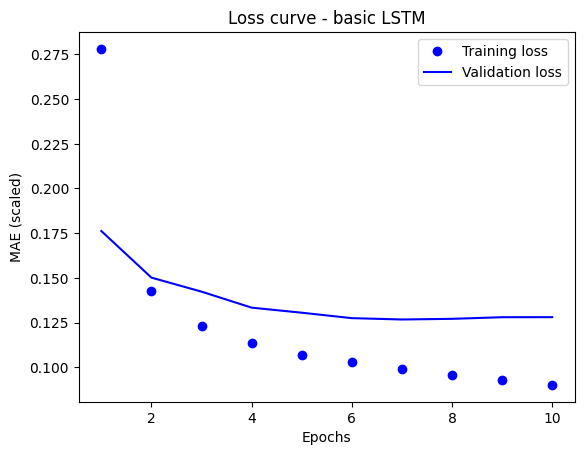

epochs run: 10 | best validation loss: 0.1267 at epoch 7


In [8]:
early_stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=SETTINGS["patience"], restore_best_weights=True)
start = time.time()
history = model.fit([X_past[train], X_future[train]], y[train],
                    validation_split=0.15,          # the LAST 15% of 2023-2025 (Keras takes it before shuffling)
                    epochs=SETTINGS["epochs"],
                    batch_size=SETTINGS["batch_size"],
                    callbacks=[early_stop],
                    verbose=2)
print(f"fit in {time.time() - start:.0f} s")

# loss curve - always look at this after a fit!
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = range(1, len(loss) + 1)
plt.plot(epochs, loss, "bo", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Loss curve - basic LSTM")
plt.xlabel("Epochs")
plt.ylabel("MAE (scaled)")
plt.legend()
plt.show()
print("epochs run:", len(loss), "| best validation loss:", round(min(val_loss), 4), "at epoch", val_loss.index(min(val_loss)) + 1)

## Part 6 · Score it like the leaderboard
On 2026, which the model never saw. **Skill** = 1 - (your error / the baseline's error) in each lead block, averaged
over the four blocks. 0 means no better than "same hour yesterday"; 1 would be perfect.

In [9]:
pred_test = model.predict([X_past[~train], X_future[~train]], verbose=0) * card["load_std"] + card["load_mean"]
lstm_blocks = mae_by_block(np.abs(pred_test - actual_test))
rows = []
skills = []
for name in lstm_blocks:
    skill = 1 - lstm_blocks[name] / baseline_blocks[name]
    skills.append(skill)
    rows.append({"lead block": name, "same hour yesterday (MW)": round(baseline_blocks[name]), "LSTM (MW)": round(lstm_blocks[name]), "skill": round(skill, 3)})
scoreboard = pd.DataFrame(rows)
print("average skill over the four lead blocks:", round(float(np.mean(skills)), 3))
scoreboard

average skill over the four lead blocks: 0.58


,lead block,same hour yesterday (MW),LSTM (MW),skill
0,1-6 h,266,112,0.579
1,7-12 h,266,112,0.578
2,13-18 h,266,112,0.579
3,19-24 h,266,110,0.586


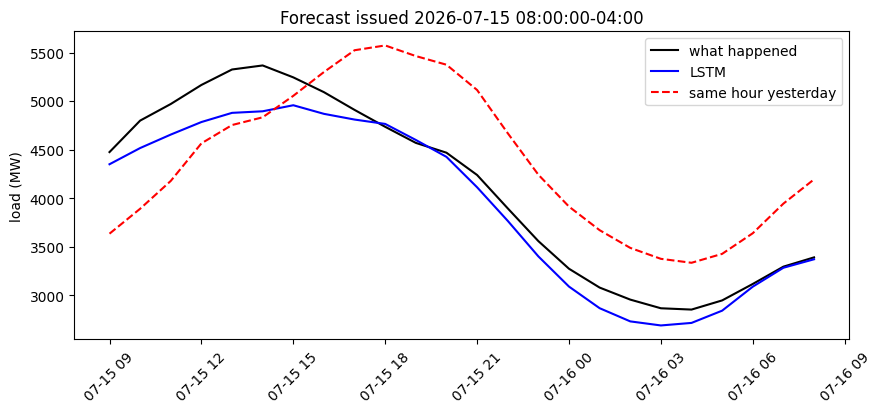

In [10]:
# one forecast up close: issued at 8 AM Connecticut time on a summer day in 2026
issue_local = pd.Timestamp("2026-07-15 08:00", tz="America/New_York")
k = int(np.argmin(np.abs((issue_hours[~train] - issue_local.tz_convert("UTC")).total_seconds())))
target_hours = pd.date_range(issue_hours[~train][k] + pd.Timedelta(hours=1), periods=horizon, freq="h").tz_convert("America/New_York")
plt.figure(figsize=(10, 4))
plt.plot(target_hours, actual_test[k], "k-", label="what happened")
plt.plot(target_hours, pred_test[k], "b-", label="LSTM")
plt.plot(target_hours, baseline_test[k], "r--", label="same hour yesterday")
plt.title("Forecast issued " + str(issue_hours[~train][k].tz_convert("America/New_York")))
plt.ylabel("load (MW)")
plt.legend()
plt.xticks(rotation=45)
plt.show()

## Part 7 · Save it for the cloud
Two files go to your Google Cloud bucket: the model (`model.keras`) and the **model card** (`model_card.json`), which
holds the look-back, the horizon and the scaling numbers so the cloud function builds the inputs exactly the way you
did. The card's `range_method` is `none` for now: this model makes one forecast per hour, no range. Part 2 changes that.

Part 8 uploads both files to your bucket.

In [11]:
card["range_method"] = "none"
card["trained_at"] = pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%dT%H:%M:%SZ")
card["test_skill_2026"] = round(float(np.mean(skills)), 3)
model.save("model.keras")
with open("model_card.json", "w") as f:
    json.dump(card, f, indent=1)

# prove the saved files give the same answer
reloaded = keras.models.load_model("model.keras")
check = reloaded.predict([X_past[~train][:5], X_future[~train][:5]], verbose=0) * card["load_std"] + card["load_mean"]
print("reloaded model reproduces the predictions:", bool(np.allclose(check, pred_test[:5], atol=0.5)))
print("saved: model.keras and model_card.json")

reloaded model reproduces the predictions: True
saved: model.keras and model_card.json


## Part 8 · Ship it to your energy project
Your energy project on Google Cloud (the setup guide) runs **`forecast-24h-dl`** every hour at :20. It loads
`energy/models/model.keras` and `model_card.json` from your bucket, builds the two inputs with the same `make_inputs` as
this notebook (the last week of live load from your ISO-NE scraper, and the newest HRRR weather forecasts), and writes the
next 24 hours to `energy/forecasts/latest.csv`.

**Once, before the first deploy:** on your fork, Settings > Secrets and variables > Actions > Variables, add
`COURSE` = `5509`, then Actions > "Deploy forecast-24h-dl" > Run workflow. (Without `COURSE`, that workflow stops
with a message and changes nothing.)

Type your project ID, set `UPLOAD = True`, and run the cells below. When the **"Allow access"** pop-up opens,
pick the **Gmail you used for Google Cloud**.

In [12]:
PROJECT_ID = "YOUR-ENERGY-PROJECT-ID"
BUCKET_NAME = PROJECT_ID              # your bucket has the same name as your project (setup guide)
UPLOAD = False                       # True once your energy project is set up

if UPLOAD and ("YOUR-ENERGY-PROJECT-ID" in PROJECT_ID or "YOUR-ENERGY-PROJECT-ID" in BUCKET_NAME):
    print("Type your PROJECT_ID and BUCKET_NAME above, then re-run this cell.")
    UPLOAD = False

if UPLOAD:
    from google.colab import auth
    from google.cloud import storage
    auth.authenticate_user()

    # CHECK 1: which Google account did you just pick in the pop-up?
    account_lines = !gcloud config get-value account
    signed_in_as = "unknown"
    if len(account_lines) > 0:
        signed_in_as = account_lines[-1].strip()
    print("1. Signed in as:", signed_in_as)

    # CHECK 2: can that account see your bucket?
    client = storage.Client(project=PROJECT_ID)
    bucket = client.bucket(BUCKET_NAME)
    try:
        bucket_ok = bucket.exists()
    except Exception as err:
        bucket_ok = False
        print("   Google says:", str(err)[:200])
    if not bucket_ok:
        raise RuntimeError("The account " + signed_in_as + " cannot see the bucket " + BUCKET_NAME + ". "
                           "Check BUCKET_NAME, or Runtime > Disconnect and delete runtime, then run again "
                           "and pick your Google Cloud Gmail in the pop-up.")
    print("2. Bucket found:", BUCKET_NAME)

    # CHECK 3: is forecast-24h-dl deployed?
    state_lines = !gcloud functions describe forecast-24h-dl --gen2 --region=us-central1 --project={PROJECT_ID} --format="value(state)"
    state = "NOT FOUND"
    if len(state_lines) > 0 and state_lines[-1].strip() in ["ACTIVE", "DEPLOYING", "FAILED"]:
        state = state_lines[-1].strip()
    print("3. forecast-24h-dl:", state)
    if state != "ACTIVE":
        print("   Add the repository variable COURSE = 5509, run 'Deploy forecast-24h-dl' on your fork's Actions tab, wait for green, then re-run this cell.")
else:
    print("UPLOAD is False: nothing is uploaded (the model is saved in this Colab session only).")

UPLOAD is False: nothing is uploaded (the model is saved in this Colab session only).


**Upload.** `energy/models/model.keras` is the **live** model (replaced every time you ship);
`energy/models/history/` keeps a copy of every model you ever shipped, named by time.

In [13]:
if UPLOAD:
    bucket.blob("energy/models/model.keras").upload_from_filename("model.keras")
    bucket.blob("energy/models/model_card.json").upload_from_filename("model_card.json")
    stamp = card["trained_at"].replace(":", "-")
    bucket.blob("energy/models/history/model_" + stamp + ".keras").upload_from_filename("model.keras")
    bucket.blob("energy/models/history/model_card_" + stamp + ".json").upload_from_filename("model_card.json")
    print("Live model:  gs://" + BUCKET_NAME + "/energy/models/model.keras", "| range_method:", card["range_method"])
    print("Kept a copy: gs://" + BUCKET_NAME + "/energy/models/history/model_" + stamp + ".keras")
else:
    print("UPLOAD is False: skipping.")

UPLOAD is False: skipping.


**Run it now.** Normally it runs by itself every hour at :20. This cell starts it right now, then checks your bucket
every 15 seconds and shows the forecast.

In [14]:
if UPLOAD:
    from datetime import datetime, timezone
    started = datetime.now(timezone.utc)
    !gcloud scheduler jobs run forecast-24h-dl-hourly --location=us-central1 --project={PROJECT_ID}
    print("Started forecast-24h-dl. Waiting for your forecast", end="")
    latest_blob = bucket.blob("energy/forecasts/latest.csv")
    ready = False
    for attempt in range(20):                 # every 15 seconds, for up to 5 minutes
        time.sleep(15)
        print(".", end="")
        if latest_blob.exists():
            latest_blob.reload()
            if latest_blob.updated > started:
                ready = True
                break
    print()
    if ready:
        import io
        latest = pd.read_csv(io.BytesIO(latest_blob.download_as_bytes()))
        print(latest[["target_hour_utc", "predicted_low_mw", "predicted_load_mw", "predicted_high_mw", "range_method"]].head(6))
    else:
        print("No new forecast after 5 minutes. Run the log cell below and paste the log into Claude.")
else:
    print("UPLOAD is False: skipping.")

UPLOAD is False: skipping.


**Optional, only for troubleshooting.** `"no_load_data"` means your ISO-NE secrets are missing or the scraper has not
collected a full week yet; `"no_model"` means the upload didn't run; `"bad_card"` explains what the card is missing;
anything with `Error` is worth pasting into Claude. A `range_method` ending in `_nws` means the class HRRR file was
missing, so the National Weather Service forecast was used instead (that's fine).

In [15]:
if UPLOAD:
    !gcloud functions logs read forecast-24h-dl --region=us-central1 --gen2 --limit=20 --project={PROJECT_ID}
else:
    print("UPLOAD is False: no log to read.")

UPLOAD is False: no log to read.


## Your turn
Before Part 2, try one change and write down what happened to the skill:
* a shorter or longer look-back (`lookback_hours` = 48 or 336),
* a GRU instead of an LSTM, or a third layer,
* dropout or `recurrent_dropout` (Module 4.3),
* a Conv1D in front of the first LSTM,
* new features: more airports (Hartford, New Haven, Groton, or nearby New York and Massachusetts stations), heating and
  cooling degree hours, or the weather a few hours earlier. For production you also need those forecasts every hour,
  so this means building your own data pipeline (the `hefty` package can fetch HRRR forecasts for any location).

Keep `make_inputs` the same unless you are ready to change the cloud function too.